# Q6 - Predict `still_active` (churn model)

**Question: will this player still be active at the flag date?**

Working assumption (to be confirmed with the data owner): `still_active` is a snapshot taken **after the end of the match log** (2026-03-03). Under it, every feature built from the match history is available *before* the label, so recency and recent-activity features are legitimate predictors, not leakage. Evidence (notebooks 01 and 05): the flag follows recency without being a rule (best single threshold = 75% agreement); 54 players flagged inactive played in the last 30 days of the log (fits "left after the log ended"); 91 flagged active have been silent for 90+ days (does not fit: the file may be a sample of the full log, or the flag may use another rule). These 91 are treated as **label noise** and checked in section 5.

Feature sets compared (same players, same split):
- **Behaviour only**: how the player plays (rates, modes, social, Elo...), without recency and without lifetime volume / duration.
- **Full history + recency**: every player feature, including lifetime volume and recency.
- **MAIN = full history + recent windows + recency**: the previous set plus features of the **latest 7 / 14 / 30 days before the end of the log** and their trend versus the previous period.
- **Early warning (first 14 days)**: a separate model for *new* players, built only from their first 14 days (section 6). Different question, weaker signal.

Split: stratified holdout (20%) + stratified 5-fold CV on the rest, plus a cohort split (train on early joiners, test on the latest joiners). Preprocessing is inside the sklearn pipelines (fitted on the training folds only). Metrics: ROC-AUC and PR-AUC (CV mean +/- std, then holdout), precision / recall at the F1-optimal out-of-fold threshold, and the same metrics for players with fewer than / at least 10 matches.

In [1]:
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import QuantileTransformer

sns.set_theme(style='whitegrid')
pl.Config.set_tbl_cols(40)
pl.Config.set_tbl_rows(40)

FEATURES_PATH: Path = Path('player_features.parquet')
DATA_PATH: Path = Path('playersmatches_test - playersmatches_test.csv')
TARGET: str = 'still_active'
SEED: int = 42
TEST_SIZE: float = 0.2
N_FOLDS: int = 5
N_WINDOW: int = 14  # days of the early window (early-warning model)
MIN_MATCHES_SEGMENT: int = 10
SILENT_DAYS: int = 90  # flagged active but silent for this long = suspected label noise
SESSION_GAP_MIN: int = 30
NUM_COLUMNS: list[str] = ['kills', 'death', 'playernb_in_match']

RECENCY: list[str] = ['days_since_last_match', 'matches_last_30d', 'matches_last_90d']
# lifetime volume / duration / end-of-life state
LIFETIME: list[str] = [
    'matches', 'tenure_days', 'active_days', 'active_weeks', 'sessions', 'decided', 'wins', 'matches_with_kd',
    'max_gap_days', 'unique_teammates', 'unique_opponents', 'elo_peak', 'elo_low', 'elo_high', 'elo_se',
    'elo_confidence', 'max_win_streak', 'max_loss_streak', 'max_session_matches', 'kills_max',
    'current_streak', 'last_result_win',
]

df_players: pl.DataFrame = pl.read_parquet(FEATURES_PATH).with_columns(pl.col('last_result_win').cast(pl.Float64))
NUMERIC: list[str] = [c for c, t in df_players.schema.items() if (t.is_numeric() or t == pl.Boolean) and c != TARGET]
FEATURES_BEHAVIOUR: list[str] = [c for c in NUMERIC if c not in RECENCY + LIFETIME]
FEATURES_FULL: list[str] = NUMERIC
print(df_players.shape, '| active share:', round(df_players[TARGET].mean(), 3))
print('behaviour only:', len(FEATURES_BEHAVIOUR), 'features | full history + recency:', len(FEATURES_FULL), 'features')

FileNotFoundError: Le fichier spécifié est introuvable. (os error 2): player_features.parquet

This error occurred with the following context stack:
	[1] 'parquet scan'
	[2] 'sink'


## 1. Recent-window features

Built from the raw match table, **relative to the end of the log** (`REF_DATE`): activity in the last 7 / 14 / 30 days, how it compares with the period just before (trend), and performance / mode mix of the last 30 days. Players with no match in a window get 0 matches and null rates (the models handle both).

In [ ]:
df_raw: pl.DataFrame = pl.read_csv(DATA_PATH, infer_schema=False, null_values=['null']).with_columns(
    pl.col('match_datetime').str.to_datetime(time_zone='UTC', strict=False),
    pl.col(*NUM_COLUMNS).cast(pl.Int64, strict=False),
    (pl.col('still_active') == 'TRUE').alias('still_active'),
)
REF_DATE = df_raw['match_datetime'].max()
print('end of the log:', REF_DATE)

df_m: pl.DataFrame = df_raw.sort('playerid', 'match_datetime', 'matchid').with_columns(
    ((pl.lit(REF_DATE) - pl.col('match_datetime')).dt.total_seconds() / 86400).alias('days_ago'),
    pl.when(pl.col('victory') == 'TRUE').then(1).when(pl.col('victory') == 'FALSE').then(0).cast(pl.Int8).alias('win'),
)


def in_window(lo: int, hi: int) -> pl.Expr:
    # match played between lo (included) and hi (excluded) days before the end of the log
    return (pl.col('days_ago') >= lo) & (pl.col('days_ago') < hi)


df_recent: pl.DataFrame = df_m.group_by('playerid').agg(
    in_window(0, 7).sum().alias('r_matches_7d'),
    in_window(0, 14).sum().alias('r_matches_14d'),
    in_window(14, 28).sum().alias('r_matches_prev14d'),
    in_window(0, 30).sum().alias('r_matches_30d'),
    in_window(30, 60).sum().alias('r_matches_prev30d'),
    pl.col('match_datetime').filter(in_window(0, 14)).dt.date().n_unique().alias('r_active_days_14d'),
    pl.col('match_datetime').filter(in_window(0, 30)).dt.date().n_unique().alias('r_active_days_30d'),
    pl.col('match_datetime').filter(in_window(0, 56)).dt.truncate('1w').n_unique().alias('r_active_weeks_8w'),
    pl.col('win').filter(in_window(0, 30)).mean().alias('r_win_rate_30d'),
    (pl.col('kills').filter(in_window(0, 30)).sum() / pl.col('death').filter(in_window(0, 30)).sum().clip(lower_bound=1)).alias('r_kd_30d'),
    (pl.col('gamemode') == 'PVP_RANKED').filter(in_window(0, 30)).mean().alias('r_share_ranked_30d'),
    pl.col('gamemode').filter(in_window(0, 30)).n_unique().alias('r_n_modes_30d'),
).with_columns(
    ((pl.col('r_matches_14d') + 1) / (pl.col('r_matches_prev14d') + 1)).alias('r_trend_14d'),
    ((pl.col('r_matches_30d') + 1) / (pl.col('r_matches_prev30d') + 1)).alias('r_trend_30d'),
)
FEATURES_RECENT: list[str] = [c for c in df_recent.columns if c.startswith('r_')]
df_main: pl.DataFrame = df_players.join(df_recent, on='playerid', how='left')
FEATURES_MAIN: list[str] = FEATURES_FULL + FEATURES_RECENT
SILENT = (pl.col(TARGET) & (pl.col('days_since_last_match') >= SILENT_DAYS))
print(len(FEATURES_RECENT), 'recent-window features | MAIN set:', len(FEATURES_MAIN), 'features | silent "active" players:', df_main.filter(SILENT).height)
df_main.group_by(TARGET).agg(*[pl.col(c).median().round(2) for c in ['r_matches_7d', 'r_matches_14d', 'r_active_days_30d', 'r_trend_14d', 'r_share_ranked_30d']], pl.len())

end of the log: 2026-03-03 13:54:20.190000+00:00


14 recent-window features | MAIN set: 82 features | silent "active" players: 91


still_active,r_matches_7d,r_matches_14d,r_active_days_30d,r_trend_14d,r_share_ranked_30d,len
bool,f64,f64,f64,f64,f64,u32
false,0.0,0.0,0.0,1.0,0.0,488
true,0.0,0.0,1.0,1.0,0.34,352


Observation:
- The two groups differ on recent activity, but the medians are low: the median active player has 1 active day in the last 30 days and a 34% ranked share in that period, the median inactive player has 0. Both groups have a median of 0 matches in the last 7 and 14 days, because many active players are not daily players, and the median trend is 1.0 in both (no matches in either period).
- 91 players are flagged active but silent for 90+ days (label noise or missing matches, see the intro).

## 2. Helpers: models, evaluation, splits

Models, from simplest to most flexible: a dummy baseline (class prior), a **single-feature baseline** (logistic regression on `days_since_last_match`: any real model must beat it), logistic regression (quantile-transformed features, L2), random forest, and a shallow, regularised gradient boosting (`HistGradientBoostingClassifier`, handles NaN natively; 840 rows would overfit a deep one).

In [ ]:
def make_models(single_feature: str) -> dict[str, tuple[Pipeline, list[str] | None]]:
    # name -> (pipeline, restrict to these columns or None for all)
    qt = lambda: QuantileTransformer(n_quantiles=100, output_distribution='normal')
    return {
        'dummy (prior)': (make_pipeline(DummyClassifier(strategy='prior')), None),
        f'1 feature ({single_feature})': (make_pipeline(SimpleImputer(strategy='median'), qt(), LogisticRegression(max_iter=1000)), [single_feature]),
        'logistic regression': (make_pipeline(SimpleImputer(strategy='median'), qt(), LogisticRegression(C=0.1, max_iter=2000)), None),
        'random forest': (make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=SEED)), None),
        'gradient boosting': (HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=20, l2_regularization=1.0, random_state=SEED), None),
    }


def pick_threshold(y: np.ndarray, proba: np.ndarray) -> float:
    # threshold maximising F1 on out-of-fold predictions
    p, r, t = precision_recall_curve(y, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    return float(t[int(np.argmax(f1))])


def evaluate(df: pl.DataFrame, features: list[str], single_feature: str, split: str = 'stratified') -> tuple[pd.DataFrame, dict]:
    # returns one row per model (CV + holdout metrics) and the fitted pipelines / holdout data
    df = df.sort('playerid')
    X, y = df.select(features).to_pandas(), df[TARGET].to_numpy().astype(int)
    if split == 'stratified':
        idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=y, random_state=SEED)
    else:  # cohort: the latest joiners are the test set
        order = np.argsort(df['first_match'].to_numpy())
        cut = int(len(df) * (1 - TEST_SIZE))
        idx_tr, idx_te = order[:cut], order[cut:]
    cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
    rows, fitted = [], {}
    for name, (model, cols) in make_models(single_feature).items():
        Xtr, Xte = X.iloc[idx_tr][cols or features], X.iloc[idx_te][cols or features]
        res = cross_validate(model, Xtr, y[idx_tr], cv=cv, scoring=['roc_auc', 'average_precision'])
        oof = cross_val_predict(model, Xtr, y[idx_tr], cv=cv, method='predict_proba')[:, 1]
        thr = pick_threshold(y[idx_tr], oof)
        model.fit(Xtr, y[idx_tr])
        proba = model.predict_proba(Xte)[:, 1]
        pred = proba >= thr
        tp = int((pred & (y[idx_te] == 1)).sum())
        rows.append({
            'model': name,
            'cv_roc_auc': f"{res['test_roc_auc'].mean():.3f} +/- {res['test_roc_auc'].std():.3f}",
            'cv_pr_auc': f"{res['test_average_precision'].mean():.3f} +/- {res['test_average_precision'].std():.3f}",
            'test_roc_auc': round(roc_auc_score(y[idx_te], proba), 3),
            'test_pr_auc': round(average_precision_score(y[idx_te], proba), 3),
            'threshold': round(thr, 2),
            'precision': round(tp / max(pred.sum(), 1), 3),
            'recall': round(tp / max((y[idx_te] == 1).sum(), 1), 3),
        })
        fitted[name] = {'model': model, 'proba': proba, 'cols': cols or features}
    fitted['_data'] = {'X_te': X.iloc[idx_te], 'y_te': y[idx_te], 'ids_te': df['playerid'].to_numpy()[idx_te], 'X_tr': X.iloc[idx_tr], 'y_tr': y[idx_tr]}
    return pd.DataFrame(rows), fitted

## 3. Three feature sets on the same players

Same split for all (stratified holdout 20% + 5-fold CV on the rest).

In [ ]:
SINGLE: str = 'days_since_last_match'
res_beh, fit_beh = evaluate(df_main, FEATURES_BEHAVIOUR, 'matches_first_30d')
res_full, fit_full = evaluate(df_main, FEATURES_FULL, SINGLE)
res_main, fit_main = evaluate(df_main, FEATURES_MAIN, SINGLE)
cmp = pd.concat({'behaviour only': res_beh, 'full history + recency': res_full, 'MAIN (+ recent windows)': res_main})
cmp.droplevel(1)[['model', 'cv_roc_auc', 'cv_pr_auc', 'test_roc_auc', 'test_pr_auc', 'precision', 'recall']]

,model,cv_roc_auc,cv_pr_auc,test_roc_auc,test_pr_auc,precision,recall
behaviour only,dummy (prior),0.500 +/- 0.000,0.420 +/- 0.002,0.500,0.417,0.417,1.000
behaviour only,1 feature (matches_first_30d),0.661 +/- 0.031,0.589 +/- 0.045,0.676,0.585,0.458,0.857
behaviour only,logistic regression,0.735 +/- 0.035,0.652 +/- 0.033,0.739,0.637,0.550,0.857
behaviour only,random forest,0.753 +/- 0.030,0.690 +/- 0.031,0.767,0.677,0.592,0.871
behaviour only,gradient boosting,0.747 +/- 0.033,0.691 +/- 0.038,0.742,0.611,0.604,0.829
full history + recency,dummy (prior),0.500 +/- 0.000,0.420 +/- 0.002,0.500,0.417,0.417,1.000
full history + recency,1 feature (days_since_last_match),0.781 +/- 0.026,0.775 +/- 0.030,0.827,0.788,0.714,0.714
full history + recency,logistic regression,0.793 +/- 0.034,0.785 +/- 0.038,0.821,0.795,0.650,0.743
full history + recency,random forest,0.821 +/- 0.026,0.812 +/- 0.023,0.824,0.792,0.644,0.829
full history + recency,gradient boosting,0.813 +/- 0.027,0.809 +/- 0.026,0.828,0.759,0.718,0.729


Observation (same split, holdout 168 players):
- **MAIN random forest: 0.822 CV ROC-AUC (0.828 holdout), 0.813 CV PR-AUC.** The full-history set gives the same (0.821): **the recent-window features add nothing measurable** (all differences are well inside the +/- 0.03 fold noise). `matches_last_30d` / `matches_last_90d` / `days_since_last_match` already carry the recent activity.
- The single feature `days_since_last_match` reaches 0.781; the best model adds only about +0.04 on top of it. Recency does most of the work.
- Behaviour only (no recency, no lifetime volume) stays at 0.75: behaviour alone predicts moderately, and the gap to MAIN (+0.07) is the value of knowing *when* the player last played.
- Random forest is the best or tied in every set; logistic regression is close, gradient boosting is not better.

## 4. Segments: short-lived vs established players

Metrics of the random forest on the holdout, split by number of matches over the whole life.

In [ ]:
def segment_report(fitted: dict, model_name: str, label: str) -> pd.DataFrame:
    d = fitted['_data']
    m = pl.DataFrame({'playerid': d['ids_te'], 'y': d['y_te'], 'proba': fitted[model_name]['proba']}).join(
        df_players.select('playerid', 'matches'), on='playerid')
    rows = []
    for seg, sub in [('< 10 matches', m.filter(pl.col('matches') < MIN_MATCHES_SEGMENT)), ('10+ matches', m.filter(pl.col('matches') >= MIN_MATCHES_SEGMENT))]:
        y, p = sub['y'].to_numpy(), sub['proba'].to_numpy()
        rows.append({'set': label, 'segment': seg, 'players': len(y), 'active share': round(y.mean(), 3),
                     'roc_auc': round(roc_auc_score(y, p), 3) if 0 < y.sum() < len(y) else np.nan,
                     'pr_auc': round(average_precision_score(y, p), 3) if y.sum() else np.nan})
    return pd.DataFrame(rows)


BEST: str = 'random forest'
pd.concat([segment_report(fit_beh, BEST, 'behaviour only'), segment_report(fit_full, BEST, 'full history + recency'), segment_report(fit_main, BEST, 'MAIN')])

,set,segment,players,active share,roc_auc,pr_auc
0,behaviour only,< 10 matches,61,0.148,0.592,0.258
1,behaviour only,10+ matches,107,0.570,0.646,0.703
0,full history + recency,< 10 matches,61,0.148,0.536,0.202
1,full history + recency,10+ matches,107,0.570,0.790,0.835
0,MAIN,< 10 matches,61,0.148,0.583,0.207
1,MAIN,10+ matches,107,0.570,0.798,0.846


Observation (segments, random forest, holdout):
- Players with **10+ matches** (107 players, 57% active): MAIN 0.80 ROC-AUC, 0.85 PR-AUC, a clear gain over behaviour only (0.65).
- Players with **fewer than 10 matches** (61 players, 15% active): close to random for every set (0.54-0.59). One-time players are the hard case, and almost all of them are inactive anyway.

## 5. Label noise: the silent "active" players

`SILENT_DAYS` = 90: players flagged active whose last match is 90+ days before the end of the log. If the flag is a later snapshot, they are either noise or players missing from the file. The MAIN model is scored on the holdout **with** and **without** them.

In [ ]:
def noise_check(fitted: dict, label: str) -> pd.DataFrame:
    d = fitted['_data']
    m = pl.DataFrame({'playerid': d['ids_te'], 'y': d['y_te'], 'proba': fitted[BEST]['proba']}).join(
        df_main.select('playerid', SILENT.alias('silent')), on='playerid')
    rows = []
    for name, sub in [('all holdout players', m), ('without silent "active"', m.filter(~pl.col('silent')))]:
        y, p = sub['y'].to_numpy(), sub['proba'].to_numpy()
        rows.append({'set': label, 'players': name, 'n': len(y), 'active share': round(y.mean(), 3),
                     'roc_auc': round(roc_auc_score(y, p), 3), 'pr_auc': round(average_precision_score(y, p), 3)})
    return pd.DataFrame(rows)


pd.concat([noise_check(fit_full, 'full history + recency'), noise_check(fit_main, 'MAIN')])

,set,players,n,active share,roc_auc,pr_auc
0,full history + recency,all holdout players,168,0.417,0.824,0.792
1,full history + recency,"without silent ""active""",154,0.364,0.892,0.830
0,MAIN,all holdout players,168,0.417,0.828,0.799
1,MAIN,"without silent ""active""",154,0.364,0.897,0.839


Observation (label noise):
- Removing the 91 silent "active" players from the holdout (14 players of 168) lifts the MAIN random forest from **0.83 to 0.90 ROC-AUC** (PR-AUC 0.80 to 0.84). A good part of the remaining error is the flag disagreeing with the match log, not the model.
- This is the quantity to settle with the data owner: if those players really are active today (matches missing from the file), the model cannot see them; if the flag is wrong for them, 0.90 is the fair estimate.

## 6. Early-warning model (secondary): the first `N_WINDOW` days of each player

A **different question**: can we tell from a new player's first 14 days who will still be there? Features come only from the matches played less than `N_WINDOW` days after the player's first match (same logic as notebook 04: session = matches less than 30 minutes apart, `draw` is neither win nor loss). Players whose first match is less than `N_WINDOW` days before the end of the log are dropped (incomplete window).

In [ ]:
df_win: pl.DataFrame = (
    df_raw.sort('playerid', 'match_datetime', 'matchid')
    .with_columns(
        pl.when(pl.col('victory') == 'TRUE').then(1).when(pl.col('victory') == 'FALSE').then(0).cast(pl.Int8).alias('win'),
        pl.col('match_datetime').diff().over('playerid').dt.total_seconds().alias('gap_s'),
        (pl.col('match_datetime') - pl.col('match_datetime').min().over('playerid')).dt.total_seconds().truediv(86400).alias('days_since_first'),
        pl.col('teammateid').str.split(',').list.len().fill_null(0).alias('n_teammates'),
    )
    .filter(pl.col('days_since_first') < N_WINDOW)  # the window: nothing after it is used
    .with_columns(
        (pl.col('gap_s').is_null() | (pl.col('gap_s') > SESSION_GAP_MIN * 60)).alias('new_session'),
        (~(pl.col('gap_s').is_null() | (pl.col('gap_s') > SESSION_GAP_MIN * 60))).shift(-1).over('playerid').alias('next_in_session'),
        (pl.col('match_datetime').dt.hour() < 6).alias('is_night'),
        (pl.col('match_datetime').dt.weekday() >= 6).alias('is_weekend'),
    )
    .with_columns(pl.col('new_session').cum_sum().over('playerid').alias('session_id'))
)

df_early: pl.DataFrame = (
    df_win.group_by('playerid')
    .agg(
        pl.col(TARGET).first(),
        pl.col('match_datetime').min().alias('first_match'),
        pl.len().alias('w_matches'),
        pl.col('match_datetime').dt.date().n_unique().alias('w_active_days'),
        pl.col('session_id').max().alias('w_sessions'),
        (pl.col('gap_s').filter(pl.col('new_session')).median() / 3600).alias('w_median_break_h'),
        (pl.col('days_since_first') < 1).sum().alias('w_matches_day1'),
        pl.col('win').drop_nulls().mean().alias('w_win_rate'),
        (pl.col('kills').sum() / pl.col('death').sum().clip(lower_bound=1)).alias('w_kd_ratio'),
        pl.col('kills').mean().alias('w_kills_per_match'),
        pl.col('death').mean().alias('w_deaths_per_match'),
        (pl.col('gamemode') == 'PVP_RANKED').mean().alias('w_share_pvp_ranked'),
        (pl.col('gamemode') == 'PVP_UNRANKED').mean().alias('w_share_pvp_unranked'),
        (pl.col('gamemode') == 'PVP').mean().alias('w_share_pvp'),
        pl.col('gamemode').n_unique().alias('w_n_modes'),
        pl.col('playernb_in_match').mean().alias('w_avg_lobby_size'),
        pl.col('n_teammates').mean().alias('w_avg_teammates'),
        pl.col('is_night').mean().alias('w_share_night'),
        pl.col('is_weekend').mean().alias('w_share_weekend'),
        pl.col('next_in_session').filter(pl.col('win') == 0).mean().alias('w_stay_after_loss'),
        pl.col('next_in_session').filter(pl.col('win') == 1).mean().alias('w_stay_after_win'),
        (pl.col('teammateid').n_unique() / pl.len()).alias('w_teammate_diversity'),
    )
    .filter(pl.col('first_match') <= REF_DATE - timedelta(days=N_WINDOW))
)
FEATURES_EARLY: list[str] = [c for c in df_early.columns if c.startswith('w_')]
df_early = df_early.with_columns(pl.col(FEATURES_EARLY).cast(pl.Float64))
print(f'window = first {N_WINDOW} days | eligible players: {df_early.height} of {df_players.height} | active share: {df_early[TARGET].mean():.3f}')
res_early, fit_early = evaluate(df_early, FEATURES_EARLY, 'w_matches')
res_early

window = first 14 days | eligible players: 819 of 840 | active share: 0.415


,model,cv_roc_auc,cv_pr_auc,test_roc_auc,test_pr_auc,threshold,precision,recall
0,dummy (prior),0.500 +/- 0.000,0.415 +/- 0.004,0.500,0.415,0.41,0.415,1.000
1,1 feature (w_matches),0.655 +/- 0.035,0.562 +/- 0.023,0.629,0.558,0.41,0.438,0.779
2,logistic regression,0.665 +/- 0.036,0.580 +/- 0.041,0.695,0.633,0.35,0.490,0.721
3,random forest,0.684 +/- 0.020,0.581 +/- 0.023,0.703,0.641,0.33,0.505,0.750
4,gradient boosting,0.652 +/- 0.022,0.564 +/- 0.030,0.666,0.620,0.26,0.440,0.809


Observation (early-warning model, first 14 days, 819 players):
- 0.65-0.68 CV ROC-AUC (random forest 0.684, holdout 0.703) against 0.655 for the number of matches alone: a weak early signal, as before. It answers a different question from the MAIN model and is kept as a secondary tool for new players.

## 7. Robustness: cohort split (MAIN)

Train on the earliest 80% of joiners, test on the latest 20%. Late joiners had less time to build a history and are mostly still active, so this checks that the model transfers to new players, not only to a random mix.

In [ ]:
res_main_c, _ = evaluate(df_main, FEATURES_MAIN, SINGLE, split='cohort')
res_main_c[['model', 'cv_roc_auc', 'test_roc_auc', 'test_pr_auc', 'precision', 'recall']]

,model,cv_roc_auc,test_roc_auc,test_pr_auc,precision,recall
0,dummy (prior),0.500 +/- 0.000,0.500,0.357,0.357,1.000
1,1 feature (days_since_last_match),0.814 +/- 0.039,0.787,0.722,0.367,0.967
2,logistic regression,0.794 +/- 0.028,0.790,0.628,0.533,0.800
3,random forest,0.827 +/- 0.024,0.802,0.713,0.495,0.833
4,gradient boosting,0.811 +/- 0.027,0.773,0.703,0.524,0.717


Observation (cohort split, MAIN):
- Train on the earliest 80% of joiners, test on the latest 20% (only 36% active in the test set): random forest 0.827 CV and 0.802 holdout ROC-AUC, similar to the random split. `days_since_last_match` alone gets 0.787 on the holdout, so on late joiners the model still adds little over recency. The holdout is small (168 players): the PR-AUC and precision are noisy.

## 8. What does the MAIN model use?

Permutation importance on the holdout (drop of ROC-AUC when one feature is shuffled; random forest), and the same for the single-feature groups to see how much comes from recency, recent windows, behaviour and lifetime volume.

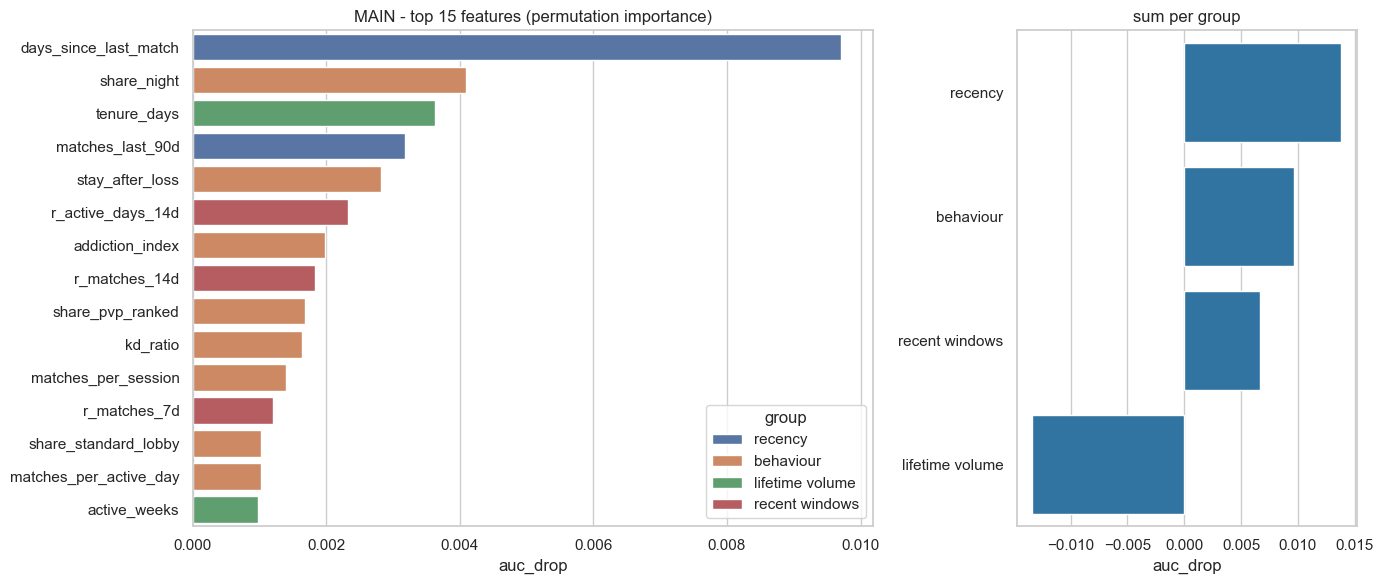

,feature,auc_drop,std,group
0,days_since_last_match,0.0097,0.0062,recency
46,share_night,0.0041,0.0028,behaviour
4,tenure_days,0.0036,0.0044,lifetime volume
2,matches_last_90d,0.0032,0.0054,recency
42,stay_after_loss,0.0028,0.0012,behaviour
73,r_active_days_14d,0.0023,0.0017,recent windows
67,addiction_index,0.0020,0.0010,behaviour
69,r_matches_14d,0.0018,0.0028,recent windows
49,share_pvp_ranked,0.0017,0.0022,behaviour
19,kd_ratio,0.0016,0.0009,behaviour


In [ ]:
d, f = fit_main['_data'], fit_main[BEST]
pi = permutation_importance(f['model'], d['X_te'][f['cols']], d['y_te'], scoring='roc_auc', n_repeats=20, random_state=SEED)
df_imp = pd.DataFrame({'feature': f['cols'], 'auc_drop': pi.importances_mean, 'std': pi.importances_std}).sort_values('auc_drop', ascending=False)
GROUP_OF: dict[str, str] = {**{c: 'recency' for c in RECENCY}, **{c: 'lifetime volume' for c in LIFETIME}, **{c: 'recent windows' for c in FEATURES_RECENT}}
df_imp['group'] = df_imp['feature'].map(GROUP_OF).fillna('behaviour')
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [2, 1]})
sns.barplot(data=df_imp.head(15), y='feature', x='auc_drop', hue='group', dodge=False, ax=axes[0])
axes[0].set_title('MAIN - top 15 features (permutation importance)')
axes[0].set_ylabel('')
sns.barplot(data=df_imp.groupby('group', as_index=False)['auc_drop'].sum().sort_values('auc_drop', ascending=False), y='group', x='auc_drop', ax=axes[1], color='tab:blue')
axes[1].set_title('sum per group')
axes[1].set_ylabel('')
fig.tight_layout()
plt.show()
df_imp.head(15).round(4)

## 9. SHAP: what drives the predictions?

SHAP values of the random forest on the **holdout players** (unseen by the model), expressed on the **churn risk**: a point to the right raises the churn risk, to the left lowers it; red = high feature value. Two models are compared: MAIN (with recency) and behaviour only (no recency, no lifetime volume), to see what the behaviour features say when recency is not available.

In [ ]:
import shap


def shap_churn(fitted: dict, model_name: str) -> shap.Explanation:
    # SHAP values on the churn risk for the holdout players of one fitted model (imputed features, as in the pipeline)
    d, f = fitted['_data'], fitted[model_name]
    imputer, forest = f['model'].steps[0][1], f['model'].steps[-1][1]
    X = pd.DataFrame(imputer.transform(d['X_te'][f['cols']]), columns=f['cols'])
    sv = shap.TreeExplainer(forest)(X)
    churn_idx = list(forest.classes_).index(0)  # still_active = False
    return shap.Explanation(values=sv.values[:, :, churn_idx], base_values=sv.base_values[:, churn_idx], data=X.values, feature_names=f['cols'])


for fitted, title in [(fit_main, 'MAIN (full history + recent windows + recency)'), (fit_beh, 'Behaviour only')]:
    exp = shap_churn(fitted, BEST)
    shap.plots.beeswarm(exp, max_display=15, show=False)
    plt.title(f'Impact on churn risk, holdout players - {title}', loc='left')
    plt.tight_layout()
    plt.show()
shap.plots.bar(shap_churn(fit_main, BEST), max_display=15, show=False)
plt.title('MAIN - mean absolute impact on churn risk', loc='left')
plt.tight_layout()
plt.show()

Observation (permutation importance, random forest):
- `days_since_last_match` is by far the most important feature (AUC drop 0.010), then `share_night`, `tenure_days`, `matches_last_90d`, `stay_after_loss` and the recent-window features `r_active_days_14d` / `r_matches_14d`. Individual drops are small and noisy because many features are correlated (the group sum of lifetime volume is even negative: shuffling one of several redundant columns changes little).
- Skill features (win rate, K/D) are not at the top, in line with notebook 05.

Conclusion:
- **MAIN model (full history + recent windows + recency): random forest, about 0.82 ROC-AUC (CV) and 0.83 on the holdout, about 0.90 once the 91 silent "active" players are set aside.** Logistic regression (0.79) is the simpler, explainable alternative.
- Most of the performance is recency (a single feature gives 0.78); recent-window features and trends add nothing measurable on 840 players. Behaviour alone gives 0.75.
- The ceiling is set by the label: confirm with the data owner how and when `still_active` was computed, and whether the match file is complete.
- The early-warning model (first 14 days, 0.68) stays a secondary tool for new players.